# Optional enhancements on a processed product

**What you will learn:** how to run each optional enhancement on a processed product, what it adds, and how to leave it off.

**What data:** a small synthetic demo flight that the first code cell builds and processes; no campaign data.

This notebook takes the same kind of demo product and runs the optional extras on it: derived quantities such as moments and a mean diameter, a check that two probes agree where their sizes overlap, an opt-in shattering filter, a corrected reacceptance step, a published depth of field, friendlier views of four raw contracts, a CF-1.10 copy of the size-distribution file, a habit rule for particles cut off by the array's edge, and a picture of the raw records the particles came from.

Every enhancement here is **off unless you ask for it**; none changes the files the engine writes. Most need the enhancements package (`pip install arrayprobe-uiops-enhancements`); without it, each of those sections prints a skip message. No campaign data: the first cell builds its own demo flight.

**Before this:** [06_read_products](../1_getting_started/06_read_products.ipynb) (shows what the output files of a run hold). **Related:** [02_probe_overlap_check](02_probe_overlap_check.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray) (the enhancements package adds an optional section).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

## 1. Build and process a demo flight


In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/7_analysis_and_outputs/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys
import tempfile
from pathlib import Path

sys.path.insert(0, "scripts")
import make_demo_flight  # noqa: E402
import netCDF4  # noqa: E402
import numpy as np  # noqa: E402
import xarray as xr  # noqa: E402
import run_flight  # noqa: E402

run_flight.log = lambda *a, **kw: None  # quiet the tool's own progress prints

tmp = tempfile.TemporaryDirectory()
out = Path(tmp.name)
# The public package runs the v3.5 engine: this sets engine, profile and a constant-TAS aircraft file.
run_flight.use_engine_35(out)
raw = out / "base160101000000.2DS"
make_demo_flight.build_demo_flight(raw, n_seconds=5)

image = run_flight.stage2(raw, out)
proc = run_flight.stage3(image, out)
sd = run_flight.stage4(proc, raw.stem, out)
print(f"proc: {proc.name}\nsd:   {sd.name}")

# The size distribution as the file stores it (raw values), used by the sections below.
with xr.open_dataset(sd, mask_and_scale=False, decode_times=False) as ds:
    bin_mid = ds["bin_mid"].values
    conc = ds["conc_minR"].values  # (time, bin)


proc: proc.base160101000000.H.nc
sd:   sd.base160101000000.H.nc


### What the sd file holds

The sd file opened with xarray: the whole Dataset, then one of its variables, the concentration per second and size bin, as a DataArray.


In [2]:
import re


def without_local_paths(data):
    """A copy whose path-valued global attributes keep only the file name.

    The file records the absolute path of the input the demo run read; showing it
    would print a folder on this machine. The file on disk is unchanged."""
    shown = data.copy()
    shown.attrs = {k: re.split(r"[/\\]", v)[-1] if isinstance(v, str) and re.match(r"(~|[A-Za-z]:|/)", v) else v
                   for k, v in data.attrs.items()}
    return shown


import xarray as xr

# load() reads the values into memory, so the file is closed when the block ends.
with xr.open_dataset(sd, decode_times=False) as f:
    sd_ds = f.load()
print(sd_ds["conc_minR"])
without_local_paths(sd_ds)


<xarray.DataArray 'conc_minR' (Time: 4, CIPcorrlen: 128)> Size: 4kB
array([[0.        , 0.        , 0.        , 0.        , 0.46858599,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.  

<xarray.Dataset> Size: 172kB
Dimensions:          (Time: 4, CIPcorrlen: 128, CIParealen: 10, Habit: 10)
Dimensions without coordinates: Time, CIPcorrlen, CIParealen, Habit
Data variables: (12/23)
    time             (Time) float64 32B 6.064e+04 6.064e+04 6.064e+04 6.064e+04
    bin_min          (CIPcorrlen) float64 1kB 0.005 0.015 0.025 ... 1.265 1.275
    bin_max          (CIPcorrlen) float64 1kB 0.015 0.025 0.035 ... 1.275 1.285
    bin_mid          (CIPcorrlen) float64 1kB 0.01 0.02 0.03 ... 1.26 1.27 1.28
    bin_dD           (CIPcorrlen) float64 1kB 0.01 0.01 0.01 ... 0.01 0.01 0.01
    conc_minR        (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    ...               ...
    Prec_rate        (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    habitmsd         (Time, CIPcorrlen, Habit) float64 41kB 0.0 0.0 ... 0.0 0.0
    Calcd_area       (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    count            (Time, CIPcorrlen) float64 4kB 0.0 0.0 0.0 ... 0.0 0.0 0.0
    mean_area_ratio  (Time, CIPcorrlen) float64 4kB nan nan nan ... nan nan nan
    mean_perimeter   (Time, CIPcorrlen) float64 4kB nan nan nan ... nan nan nan
Attributes: (12/28)
    Software:                                    UIOOPS_v3.5
    Creation_Time:                               2026/10/30 21:00:29
    Description:                                 Contains size distributions ...
    Project:                                     ORACLES
    Data_Source:                                 proc.base160101000000.H.nc
    Probe_Type:                                  2DS
    ...                                          ...
    arrayprobe_tas_qc_convention:                arrayprobe-tasqc-1
    arrayprobe_tas_seconds_total:                4
    arrayprobe_tas_substituted_count:            0
    arrayprobe_tas_substituted_ranges:           
    arrayprobe_tas_substituted_reasons:          above-cutoff:0;non-finite:0;...
    arrayprobe_tas_uncertainty:                  none: every second has a mea...

### Particles counted in each size bin

The sd file's `count` summed over the flight, against each bin's midpoint diameter.


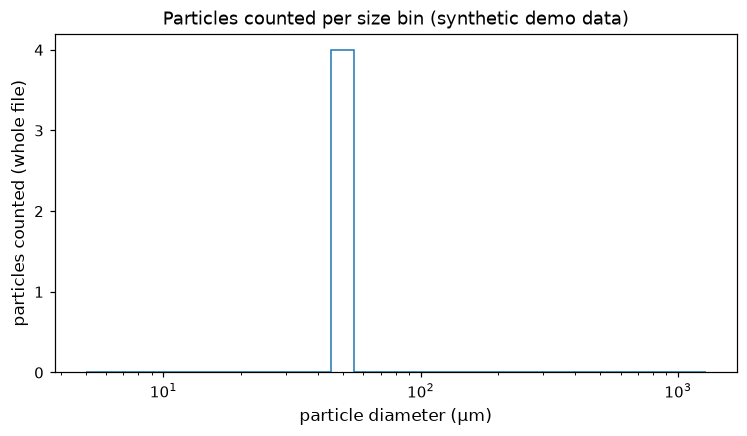

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from matplotlib.ticker import MaxNLocator

counts = np.atleast_2d(sd_ds["count"].values).sum(axis=0)
# Bin edges in micrometres: each bin's lower edge, then the last bin's upper edge.
edges_um = 1000.0 * np.append(sd_ds["bin_min"].values, sd_ds["bin_max"].values[-1])
fig, ax = plt.subplots(figsize=(8, 4))
ax.stairs(counts, edges_um)
ax.set_xscale("log")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlabel("particle diameter (µm)")
ax.set_ylabel("particles counted (whole file)")
ax.set_title("Particles counted per size bin (synthetic demo data)")
plt.show()


*Figure 1. Particles counted in each size bin over the whole synthetic demo flight. A demo flight this short counts few or no particles, so the line can sit at zero; a real flight's sd file fills it.*


## 2. Derived quantities: PSD moments, D_m, and a leg with its uncertainty

`sizeDist` stops where UIOOPS stops -- one second at a time, with a total number
concentration `n` and a Fu (1996) effective radius `re`. Everything past that,
every user has historically rewritten: the moment integrals, the mass-weighted
mean diameter, the flight-leg averages.

`arrayprobe_enhancements.analysis` is that layer. It reads the arrays this file
already has, writes nothing back, and changes no computed number -- which is why
it can sit outside the port without touching the fidelity claim.

Three things worth knowing before you use it:

- **`moment(..., order=0)` on `conc_minR` reproduces `sizeDist`'s own `n`.** That
  is the check that the moment integral agrees with the file it came from, and
  it is asserted in the module's tests against the tracked fixture. Compute it
  and compare before trusting any higher order.
- **A leg's Poisson uncertainty is not the per-second uncertainties in
  quadrature.** The whole leg's bin-seconds are one Poisson process, because a
  sum of independent Poisson counts is itself Poisson however many axes it was
  summed over.
- **The first five bins are still excluded.** Nothing in this layer re-applies
  the used-bin convention for you; §3's slice is yours to carry forward.

This is the one place these notebooks reach outside the port. If the import
below fails, the cell says what to install and the rest of the notebook is
unaffected.

In [4]:
try:
    from arrayprobe_enhancements import analysis
except ImportError:
    analysis = None
    print("arrayprobe_enhancements is not installed, so this section is skipped.\n"
          "It ships separately from the core package:  pip install arrayprobe-uiops-enhancements\n"
          "Everything above this cell is the core package alone and needs nothing extra.")

if analysis is not None:
    with xr.open_dataset(sd, mask_and_scale=False, decode_times=False) as ds:
        bin_min = ds["bin_min"].values
        bin_max = ds["bin_max"].values
        n_written = ds["n"].values
        count = ds["count"].values
        mass = ds["mass"].values

    bin_mid_mm = (bin_min + bin_max) / 2.0
    bin_dD_mm = bin_max - bin_min
    print(f"read {bin_mid_mm.size} size bins and {n_written.size} second(s) from the sd file")

read 128 size bins and 4 second(s) from the sd file


The cell below checks the moments against the file's own total, then prints the mass-weighted mean diameter and the leg's particle count with its Poisson uncertainty.


In [5]:
if analysis is not None:
    # M0 of the number-concentration density IS the total number concentration.
    # Comparing it against the file's own `n` is the check that this layer and
    # `sizeDist` agree before any higher moment is believed.
    m0 = analysis.moment(bin_mid_mm, bin_dD_mm, conc, order=0)
    finite = np.isfinite(m0) & np.isfinite(n_written)
    if finite.any():
        worst = np.nanmax(np.abs(m0[finite] - n_written[finite]))
        print(f"M0 vs the file's own n:  max |difference| = {worst:.3e} cm-3")
    else:
        print("this fixture has no second with a finite n to compare against")

    d_m = analysis.mass_weighted_mean_diameter(bin_mid_mm, bin_dD_mm, mass)
    finite_dm = d_m[np.isfinite(d_m) & (d_m > 0)]
    if finite_dm.size:
        print(f"mass-weighted mean diameter D_m: {finite_dm.mean():.4g} mm "
              f"over {finite_dm.size} second(s) with mass")
    else:
        print("no second in this fixture carries a positive mass density")

    total, relative, absolute = analysis.leg_total_count_with_uncertainty(count)
    if total > 0 and np.isfinite(relative):
        print(f"whole-file particle count: {total:,.0f} "
              f"+/- {absolute:,.0f} ({100 * relative:.2f} % Poisson)")
    else:
        # The quickstart's synthetic flight bins nothing: five particles, none
        # of which survive to a size bin. Said plainly rather than printed as
        # "0 +/- nan", which reads like a broken tool on a page whose whole job
        # is showing what working output looks like.
        print("this demo flight bins no particles, so there is no leg total to "
              "report -- run the cell against a real flight's sd file to see one")

M0 vs the file's own n:  max |difference| = 5.421e-20 cm-3
mass-weighted mean diameter D_m: 0.05 mm over 4 second(s) with mass
whole-file particle count: 4 +/- 2 (50.00 % Poisson)


### Two probes, one size range

Before merging the size distributions of two probes that cover overlapping sizes (for
example a 2D-S and an HVPS), check that they agree where their size ranges overlap.
`probe_crossover` does this second by second: it compares each probe's concentration over
the shared range, on the log ratio, against the counting (Poisson) error from the sd file's
own `count`. Each second is labelled agree, a_higher, b_higher, insufficient (too few
particles) or missing (no data). It merges nothing.

No tracked example file holds two probes for the same interval, so the cell runs one input
through the two engines (two sd files with different size bins). It shows the call and the
result, not a two-probe finding. Point `PROBE_A` and `PROBE_B` at your own pair of sd files.


In [6]:
# Two probes, one size range: arrayprobe_enhancements.probe_crossover (merges nothing).
try:
    from arrayprobe_enhancements import probe_crossover
except ImportError:
    probe_crossover = None
    print("arrayprobe_enhancements is not installed, so this cell is skipped.")

if probe_crossover is not None:
    PROBE_A = Path("tests/data/v35_probetype1_sizedist/test_cip.sd.nc")   # a synthetic CIP product
    PROBE_B = Path("tests/data/v35_sizedist/main.nc")           # a second synthetic product
    result = probe_crossover.crossover_diagnostic(PROBE_A, PROBE_B)  # window_s=60 pools seconds
    lo, hi = result.size_range
    print(f"shared range {lo:g}-{hi:g} mm; bin edges aligned: {result.edges_aligned}")
    print(f"seconds by status: {result.counts_by_status()}")
    print(f"flagged {result.n_flagged} of {result.n_tested} tested; counting noise "
          f"alone would flag {result.expected_false_flags:.2f} at |z| > {result.z_threshold:g}")


shared range 0.2-1.8 mm; bin edges aligned: True
seconds by status: {'missing': 0, 'insufficient': 0, 'agree': 0, 'a_higher': 0, 'b_higher': 0}
flagged 0 of 0 tested; counting noise alone would flag 0.00 at |z| > 3


### The inter-arrival shattering policy (opt-in, off by default)

When a large ice particle shatters on the probe's tips, the fragments arrive very close
together in time. McFarquhar et al. (2017, p. 11.21) describe three threshold rules and
removing "that particle and one or two adjacent particles". `InterArrivalPolicy()` with no
arguments is the UIOOPS behaviour and changes nothing; turn it on with `enabled=True`.
`rule` chooses which of the three computed thresholds goes into the threshold file; with the
single 6 microsecond default used here, only `neighbours` has an effect.


In [7]:
# Opt-in, default OFF: the inter-arrival shattering policy.
try:
    from arrayprobe_enhancements.intarr_policy import (InterArrivalPolicy,
                                                       flag_shattered_by_second)
except ImportError:
    InterArrivalPolicy = None
    print("arrayprobe_enhancements is not installed, so this cell is skipped.")

if InterArrivalPolicy is not None:
    with xr.open_dataset(proc, mask_and_scale=False, decode_times=False) as ds:
        ia = np.asarray(ds["inter_arrival"].values, dtype=float)
        sec = np.asarray(ds["Time"].values, dtype=float)
    thresh = 6e-6  # the per-probe default sizeDist falls back to without a threshold file
    off = InterArrivalPolicy()
    on = InterArrivalPolicy(enabled=True, rule="min_fitted", neighbours=2)
    for label, policy in (("OFF (UIOOPS)", off), ("ON, neighbours=2", on)):
        n = int(flag_shattered_by_second(ia, thresh, sec, policy=policy).sum())
        print(f"{label}: {n} of {ia.size} demo particles flagged 'S'")
    # This demo's particles are one per second, each opening its record (inter-arrival 0),
    # so both states flag all of them. A hand-built second with one short gap shows the
    # neighbour count at work:
    one_second = [0.01, 0.01, 1e-7, 0.01, 0.01]
    for k in (0, 1, 2):
        policy = off if k == 1 else InterArrivalPolicy(enabled=True, neighbours=k)
        mask = flag_shattered_by_second(one_second, thresh, [0] * 5, policy=policy)
        print(f"neighbours={k}: {mask.astype(int).tolist()}")


OFF (UIOOPS): 5 of 5 demo particles flagged 'S'
ON, neighbours=2: 5 of 5 demo particles flagged 'S'
neighbours=0: [0, 0, 1, 0, 0]
neighbours=1: [0, 1, 1, 0, 0]
neighbours=2: [0, 1, 1, 1, 0]


## 3. An enhancement you can isolate: reacceptance over every shattering event (D3)

Every enhancement in `arrayprobe_enhancements` is OFF unless a run's `[enhancements]` table
names it `true` (or sets `all = true`), this one included. From Python its parameter defaults
off too. UIOOPS's shattering reacceptance
(`sizeDist.m:1036`/`:1169` in v3.1.4, `:1213`/`:1346` in v3.5) scans only the *first* shattering
event in a second, and nothing at all when the second opens mid-event. The UIOOPS developers fixed
this themselves in v3.5's new `iaThreshType = 3` block (`sizeDist.m:1403-1427`, one bracket from
the first event start to the last event end); `reaccept_every_event_fix` applies *their* fix to
the type-1 and type-2 paths of either engine. It has no effect on a run that never turns
reacceptance on. From Python, turn it on with the parameter `reaccept_every_event=True`; in a run
config, name it:

```toml
[enhancements]
reaccept_every_event_fix = true
```

Details: `enhancements_uiops/docs/CORRECTIONS.md`, part `reaccept_every_event_fix.py`.

## 4. The published 2D-S depth of field (`published_dof`, opt-in in the enhancements package)

The engine's depth of field is `calc_sa_randombins.m:42`'s constant, the same in v3.1.4 and v3.5.
`arrayprobe_enhancements.published_dof` replaces it with Gurganus & Lawson (2018, JTECH 35,
Eq. 1, p. 1534): `DOF = 2 c r^2 / lambda`, **c = 8 +/- 0.2**, measured on the SPEC 2D-128, and
airspeed-independent up to the 190 m/s their flight and spinning-disk tests reached (p. 1550).
`arrayprobe-enhanced run` applies it when a run config's `[enhancements]` table sets
`published_dof = true`. From Python every function takes `enabled=False`, so
`enabled=True` here. HVPS, CIP, PIP and 2D-C are refused by name: neither paper
measured them. The demo flight bins almost nothing and the v3.5 sd file carries no `sample_vol`,
so the cell prints the per-bin depth-of-field ratio itself; on a
populated 2D-S file every bin under ~0.11 mm gains +0.68 %.

This cell opens the file with `netCDF4`, to read the raw, on-disk values exactly as stored.


In [9]:
try:
    from arrayprobe_enhancements import published_dof
except ImportError:
    published_dof = None
    print("arrayprobe_enhancements is not installed, so this section is skipped.")

if published_dof is not None:
    from arrayprobe.readers.tasinfo import load_tas_info
    from arrayprobe_uiops.sizedist_tables import probe_defaults

    _t, tas = load_tas_info(out / f"{raw.stem}.tas.csv")   # the reader's own TAS sidecar
    with netCDF4.Dataset(str(sd)) as ds:
        attrs = ds.ncattrs()
        probe = ds.getncattr("Probe Type" if "Probe Type" in attrs else "Probe_Type")
        armdst = probe_defaults(ds.getncattr("Project"), probe, version="3.5").armdst
    # enabled=True is the opt-in; without it the file is copied byte-for-byte
    sd_on = published_dof.corrected_sd_file(sd, out / "sd.published_dof.nc",
                                            armdst=armdst, tas=tas, enabled=True)
    # DOF_published / DOF_engine per bin; the file writer divides the volume-normalised
    # variables by it (the v3.5 sd file carries no sample_vol, so the ratio is read directly)
    ratio = published_dof.dof_ratio(bin_mid, armdst, probe=probe, tas=tas)
    moved = np.nonzero(ratio != 1)[0]
    print(f"probe {probe}, armdst {armdst} mm, TAS {tas.min():.0f}-{tas.max():.0f} m/s")
    print(f"{moved.size} of {ratio.size} bins change depth of field "
          f"(bin_mid <= {bin_mid[moved].max():.3f} mm), each by x{ratio[moved[0]]:.6f}")


probe 2DS, armdst 63.0 mm, TAS 130-130 m/s
11 of 128 bins change depth of field (bin_mid <= 0.110 mm), each by x0.993283


## 5. A friendlier view of four raw contracts (`arrayprobe.friendly`)

Reading these files from Python surfaces a few contracts MATLAB's own loop shape forces --
see [Conventions and terms](../../docs/09-conventions.md#preserved-bugs) for the
full list, and [the generated reference](../../docs/31-api-friendly.md).
`arrayprobe.friendly` re-views each one without changing the number the raw function computed
or sitting anywhere on the reproduction path -- the port's own functions are untouched.


In [10]:
from arrayprobe import friendly
from arrayprobe_uiops import spec

# 6a. all_record_headers -- iter_record_windows yields n-1 windows because
# read_binary_SPEC.m's raw loop never treats the file's last record as a
# primary; this re-view adds that one missing header back, unchanged data.
windows = list(spec.iter_record_windows(raw))
headers = friendly.all_record_headers(raw)
print(f"iter_record_windows: {len(windows)} window(s); "
      f"all_record_headers: {len(headers)} header(s) -- one more, the last record's own")

# 6c. load_mask_csv -- the terminator-less .MK.csv, re-exported as-is (it already
# was the friendly view: read_binary_SPEC.m:313-315 drops every line terminator).
mk_path = out / "demo.MK.csv"
mk_path.write_text("1, " + ", ".join(str(i) for i in range(18)) + ", ")
records = friendly.load_mask_csv(mk_path)
print(f"parsed {len(records)} mask record(s) from a file with no newlines at all: {records[0]}")


iter_record_windows: 9 window(s); all_record_headers: 10 header(s) -- one more, the last record's own
parsed 1 mask record(s) from a file with no newlines at all: MaskRecord(time_word=1, mask_bits=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15), time_start=16, time_end=17)


## 6. An opt-in CF-1.10 copy of the sd file

The port's `sd` file keeps UIOOPS's own unit strings (`100/100`, `HHMMSS`, `g/cm-4`, ...)
because they are part of its output contract. `cf_export` (in `arrayprobe_enhancements`,
**off unless you call it**) writes a *sibling* file a CF reader can use: a real time
coordinate, size bins with `bounds`, SI units with each variable's rescale factor recorded,
and `standard_name` only where the CF table has one. Four UIOOPS unit strings do not describe
their values (`vt`, `Prec_rate`, `habitmsd`, `re`); the export says what each really is.

The flight date is yours to supply -- an `sd` file's time is `HHMMSS` only. This demo's raw
file was named `base160101000000`, so the cell passes 2016-01-01.

This cell opens the file with `netCDF4`, to read the raw, on-disk values exactly as stored.


In [12]:
try:
    from arrayprobe_enhancements import cf_export
except ImportError:
    cf_export = None
    print("arrayprobe_enhancements is not installed, so this section is skipped.")

if cf_export is not None:
    import datetime as dt

    cf_path = sd.with_name(sd.name.replace(".nc", ".cf.nc"))
    report = cf_export.export(sd, cf_path, flight_date=dt.date(2016, 1, 1))
    with netCDF4.Dataset(str(cf_path)) as ds:
        print("Conventions:", ds.Conventions, "| engine:", ds.enhancements_engine)
        t = ds.variables["time"]
        print("time units:", t.units)
        print("bin coordinate:", ds.variables["bin"].units,
              "bounds ->", ds.variables["bin"].bounds)
        for name in ("conc_minR", "vt", "Prec_rate", "habitmsd", "ar"):
            v = ds.variables[name]
            print(f"{name:10s} {v.arrayprobe_source_units!r:>10} -> {v.units!r:12} "
                  f"x {v.arrayprobe_cf_scale:g}")
    with netCDF4.Dataset(str(sd)) as ds:
        print("port file still says Conventions:", getattr(ds, "Conventions", "(none)"))


Conventions: CF-1.10 | engine: 3.5
time units: seconds since 2016-01-01T00:00:00Z
bin coordinate: m bounds -> bin_bounds
conc_minR      'cm-4' -> 'm-4'        x 1e+08
vt            'g/cm4' -> 'm-3 s-1'    x 1e+08
Prec_rate     'mm/hr' -> 'kg m-3 s-1' x 100000
habitmsd     'g/cm-4' -> 'kg m-4'     x 100000
ar          '100/100' -> '1'          x 1
port file still says Conventions: (none)


## 7. Habit for accepted partial images (Korolev & Sussman 2000) -- an opt-in you can switch off

Neither UIOOPS version classifies a particle cut off by the array's edge with a rule built for
partial images: UIOOPS v3.1.4 runs Holroyd's complete-image rules on the truncated silhouette, and v3.5
withholds a habit (`'C'`). `arrayprobe_enhancements.partial_image_habit` implements Korolev &
Sussman (2000)'s RABIT, which retrieves the habit *fractions* of a whole ensemble and counts its
accepted partials too. It is opt-in: `partial_image_habit = true` under `[enhancements]` switches it on,
alone or beside others.

Two honest limits, both printed below: the paper's only retrieval matrices are for a 32-diode
OAP-2DC and do not transfer (its p. 1057), so on this 128-diode 2D-S the fractions are
**refused**; and this demo flight has no edge-touching particles, so the census has no partials
to count.

This cell opens the file with `netCDF4`, to read the raw, on-disk values exactly as stored.


In [13]:
try:
    from arrayprobe_enhancements import partial_image_habit as pih, registry
except ImportError:
    pih = None
    print("arrayprobe_enhancements is not installed, so this section is skipped.")

if pih is not None:
    from arrayprobe.render import reconstruct_particle_image

    with netCDF4.Dataset(str(image)) as image_ds, netCDF4.Dataset(str(proc)) as proc_ds:
        silhouettes = [reconstruct_particle_image(image_ds, proc_ds, i)
                       for i in range(proc_ds.dimensions["time"].size)]
    n_diodes = silhouettes[0].shape[1]
    census = pih.census(silhouettes, n_diodes)
    print(f"groups: {census.groups}")
    print(f"retrievable: {census.n_complete} complete, {census.n_partial} accepted partial")
    try:
        pih.classify_population(silhouettes, n_diodes=n_diodes, pixel_um=10.0)
    except pih.NoRetrievalMatrixForProbe as exc:
        print("fractions refused:", str(exc).split(" -- ")[0])
    default = registry.resolve(None)["partial_image_habit"]
    opted_in = registry.resolve({"partial_image_habit": True})["partial_image_habit"]
    print(f"default: {'ON' if default else 'OFF'}; with partial_image_habit = true: "
          f"{'ON' if opted_in else 'OFF'}")


groups: {'tiny': 5}
retrievable: 0 complete, 0 accepted partial
fractions refused: R1 matrix was built for NRC PMS OAP-2DC, vertical laser beam (32 diodes, 25 um); these images are 128 diodes at 10 um. Korolev & Sussman (2000) p. 1057: new retrieval matrices should be created for different probe configurations
default: OFF; with partial_image_habit = true: ON


## 8. The records themselves: the record strip

Every view above reads the proc file one particle at a time. The record strip reads the
*decoded buffer* the particles were framed from: whole 1700-slice records stacked one above the
next, each particle's shadow coloured by its reject code (accepted is black; a hollow-flagged `'h'` particle is still accepted, because v3.5 `sizeDist.m:1460` counts `'0'`, `'H'`, `'h'`, `'u'` and `'R'`), the boundary slices
between particles in cyan, and shadow that no particle window claims in grey -- here, the timing
word that follows every boundary. `arrayprobe view strip` writes the same picture to a file, and
the triage server serves it at `/strip/<flight>`.

This cell opens the file with `netCDF4`, to read the raw, on-disk values exactly as stored.


In [14]:
import matplotlib.pyplot as plt
from arrayprobe import diagnostic_views as views

with netCDF4.Dataset(str(image)) as im, netCDF4.Dataset(str(proc)) as pr:
    strip = views.record_strip(im, pr, 1, 5)
for p in strip.particles:
    print(f"proc row {p.index}: record {p.record}, slices {p.first_slice}-{p.last_slice}, "
          f"reject {p.reject!r}, habit {p.habit!r}")
print(f"{int(strip.boundary.sum())} boundary slice(s) across {len(strip.records)} record(s)")


proc row 0: record 1, slices 1-4, reject 'h', habit 's'
proc row 1: record 2, slices 1-4, reject 'h', habit 's'
proc row 2: record 3, slices 1-4, reject 'h', habit 's'
proc row 3: record 4, slices 1-4, reject 'h', habit 's'
proc row 4: record 5, slices 1-4, reject 'h', habit 's'
5 boundary slice(s) across 5 record(s)


The cell below names every colour in a legend and draws records 1-5, one row each, cropped to the slices that hold particles.


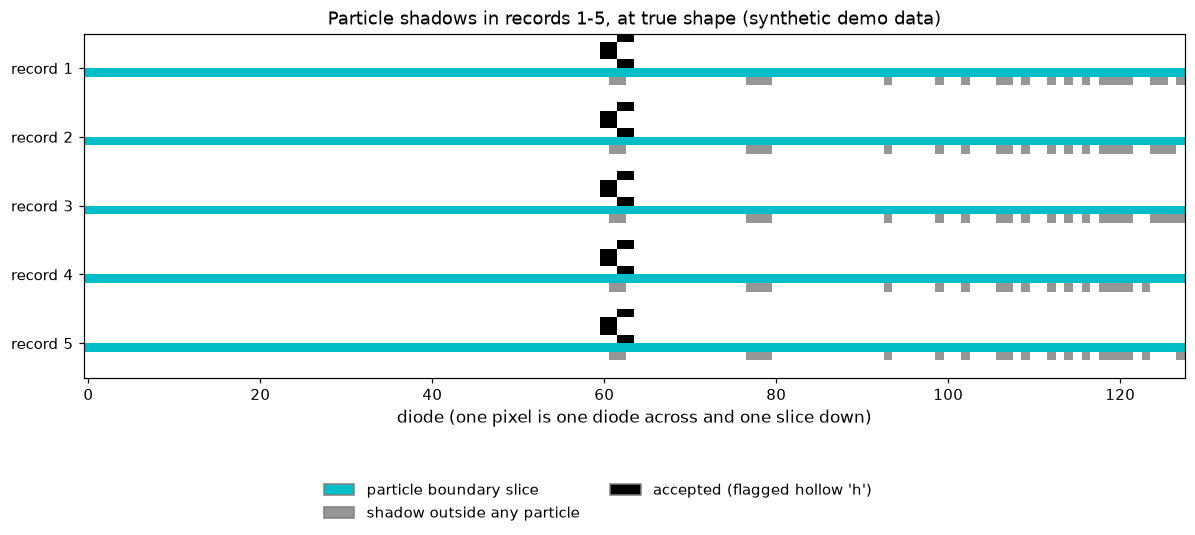

In [15]:
from matplotlib.patches import Patch
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})
img, palette = views.strip_index_image(strip)
rgb = np.asarray(palette, dtype=np.uint8)[img]
used = np.flatnonzero((img > 1).any(axis=0))       # columns with anything but background/band
right = min(img.shape[1], used.max() + 3)          # crop the empty end of each record
role_names = {2: "particle boundary slice", 3: "shadow outside any particle"}
REJECT_WORDS = {"a": "aspect ratio too large", "t": "elongated and touching the edge",
                "p": "too few shadowed diodes", "s": "split image", "z": "zero area",
                "f": "zero area"}
HOLLOW_KEPT = {"0": "clean", "H": "flagged hollow", "h": "flagged hollow",
               "u": "flagged hollow", "R": "reaccepted"}
kept = sorted({p.reject for p in strip.particles if p.category(strip.colour_by) == "accepted"})
accepted_label = "accepted (" + ", ".join(sorted({f"{HOLLOW_KEPT[c]} '{c}'" for c in kept})) + ")"
names = {**role_names, **{5 + k: (accepted_label if c == "accepted"
                                  else "rejected: " + REJECT_WORDS.get(c.split()[-1], c))
                          for k, c in enumerate(strip.categories)}}
handles = [Patch(facecolor=np.array(palette[i]) / 255, edgecolor="0.5", label=names[i])
           for i in sorted(names) if (img == i).any()]
n_diodes = strip.shadow.shape[2]
band = img.shape[0] // len(strip.records)
rows, ticks, top = [], [], 0
for k in range(len(strip.records)):
    sel = slice(k * band + band - n_diodes, (k + 1) * band)
    used = np.flatnonzero((img[sel] > 1).any(axis=0))
    part = rgb[sel, max(used.min() - 1, 0):used.max() + 2].transpose(1, 0, 2)  # slices run down
    rows += [part, np.full((1, n_diodes, 3), 255, np.uint8)]
    ticks.append((top + part.shape[0] / 2, f"record {k + 1}"))
    top += part.shape[0] + 1
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.imshow(np.vstack(rows), aspect="equal", interpolation="nearest")
ax.set_yticks([t for t, _ in ticks], [s for _, s in ticks])
ax.set_xlabel("diode (one pixel is one diode across and one slice down)")
ax.set_title("Particle shadows in records 1-5, at true shape (synthetic demo data)", fontsize=12)
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=10)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()


*Figure 2. Records 1-5 of the synthetic demo image file, one row each, drawn at true shape (one pixel is one diode across and one slice down) and cropped to the slices that hold particles. The legend below names every colour drawn; the boundary slice marks where one particle ends and the next begins.*

## Where to go next

- [`02_probe_overlap_check.ipynb`](02_probe_overlap_check.ipynb) -- the two-probe overlap check in full.
- [`06_provenance.ipynb`](06_provenance.ipynb) -- reading which engine and configuration made a file.
- `enhancements_uiops/docs/CORRECTIONS.md` -- every enhancement, its evidence and how to turn it on.
